# ENGE 707 Assessment 3: Cat & Dog Facial Feature Classification

> Expected data folder: `train/`, `test/`, `train_labels.csv`, `sample_submission.csv`. Training on a Kaggle GPU takes roughly 3–5 minutes per epoch with the default settings.

## 0. Setup and configuration

In [1]:
import os, sys, glob, json, random, hashlib, time, platform
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter, UnidentifiedImageError

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score, ConfusionMatrixDisplay)

In [ ]:
# ---------------- Configuration: every tunable setting ----------------
CFG = dict(
    DATA_DIR    = "Data/",       # set to None = auto-detect (/kaggle/input/...).
    OUT_DIR     = "outputs",
    SEED        = 42,
    IMG_SIZE    = 224,           # ImageNet-pretrained backbones are trained at 224x224
    BATCH_SIZE  = 32,
    EPOCHS      = 12,            # upper limit; early stopping may end sooner (~60k images per epoch)
    FREEZE_EPOCHS = 2,           # train only the new head first, then fine-tune everything
    LR          = 3e-4,          # AdamW learning rate for fine-tuning
    HEAD_LR     = 1e-3,          # higher LR while only the new head is training
    WEIGHT_DECAY= 1e-4,
    LABEL_SMOOTHING = 0.1,
    DROPOUT     = 0.3,
    VAL_SIZE    = 0.2,           # 80/20 stratified hold-out split
    PATIENCE    = 5,             # early stopping patience (epochs without val-loss improvement)
    MODEL_NAME  = "efficientnet_b0",   # or "resnet50", "convnext_tiny"
    NUM_WORKERS = 2,
    TTA         = True,          # average predictions over original + horizontally flipped image
    CLASS_WEIGHTS = False,       # True = weight the loss by inverse class frequency (an experiment to compare)
    EXPERIMENT  = "baseline",    # label for the experiment log; change for each run you report
)

def seed_everything(seed):
    # Fix every source of randomness so results can be reproduced
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(CFG["SEED"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path(CFG["OUT_DIR"]); OUT.mkdir(parents=True, exist_ok=True)

# Record the environment for reproducibility (cite these versions in the report)
print(f"Python {platform.python_version()} | torch {torch.__version__} | "
      f"torchvision {torchvision.__version__} | device: {DEVICE}")

Python 3.14.7 | torch 2.14.1+cpu | torchvision 0.29.1+cpu | device: cpu


## 1. Dataset exploration and understanding

### Locate the data and build the image tables
Competition files:
* train_labels.csv - image_id, class for 63,660 labelled images (ids zero-padded, e.g. 00001)
* sample_submission.csv - image_id, class for 29,443 test images (ids **not** padded, e.g. 1)
* train/ and test/ - the image files, named by id

Train and test ids overlap numerically (both start at 1), so ids are only unique **within** each folder. Files are matched to ids by the integer value of their file name, which works whether or not the names are zero-padded.

In [3]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
CLASSES_EXPECTED = ["CatEye","DogEye","CatFace","DogFace","CatMouth","DogMouth","CatNose","DogNose"]

def find_data_dir():
    if CFG["DATA_DIR"]:
        return Path(CFG["DATA_DIR"])
    # On Kaggle the competition is mounted under /kaggle/input/<name>/ (or /kaggle/input/competitions/<name>/)
    hits = [Path(p).parent for p in glob.glob("/kaggle/input/**/train_labels.csv", recursive=True)]
    if hits:
        return hits[0]
    raise FileNotFoundError("Set CFG['DATA_DIR'] to the folder containing train_labels.csv")

DATA = find_data_dir()
print("Data folder:", DATA)
for item in sorted(DATA.iterdir()):
    n = f"{sum(1 for _ in item.iterdir())} files" if item.is_dir() else f"{item.stat().st_size/1e3:.0f} KB"
    print(f"  {item.name:<25} {n}")

def find_subdir(name):
    # The image folder may be nested one level (e.g. train/train/); return the level holding the images
    d = DATA / name
    while d.is_dir():
        subs = [s for s in d.iterdir() if s.is_dir()]
        if len(subs) == 1 and not any(p.suffix.lower() in IMG_EXTS for p in d.iterdir()):
            d = subs[0]
        else:
            return d
    raise FileNotFoundError(f"No '{name}' folder in {DATA}")

def index_folder(folder):
    # {integer id: file path}; '00042.jpg' and '42.jpg' both map to 42
    out = {}
    for p in folder.iterdir():
        if p.suffix.lower() in IMG_EXTS and p.stem.isdigit():
            out[int(p.stem)] = str(p)
    return out

TRAIN_DIR, TEST_DIR = find_subdir("train"), find_subdir("test")
train_files, test_files = index_folder(TRAIN_DIR), index_folder(TEST_DIR)
example = next(iter(train_files.values()))
print(f"\nExample file name: {Path(example).name} | train files: {len(train_files)} | test files: {len(test_files)}")

Data folder: data
  sample_submission.csv     429 KB
  test                      1 files
  train                     1 files
  train_labels.csv          942 KB

Example file name: 00001.jpg | train files: 63660 | test files: 29443


In [4]:
# dtype=str keeps ids exactly as written (zero padding in train, none in the sample submission)
labels = pd.read_csv(DATA / "train_labels.csv", dtype=str)
sample_sub = pd.read_csv(DATA / "sample_submission.csv", dtype=str)
print("train_labels.csv:", labels.shape, "| sample_submission.csv:", sample_sub.shape)
display(labels.head(3)); display(sample_sub.head(3))

train_df = pd.DataFrame({
    "image_id": labels.image_id,
    "path": labels.image_id.astype(int).map(train_files),
    "label": labels["class"],
})
test_df = pd.DataFrame({
    "image_id": sample_sub.image_id,              # kept verbatim for the submission file
    "path": sample_sub.image_id.astype(int).map(test_files),
})

# Integrity checks: every id needs a file, and every file needs an id
miss_tr, miss_te = train_df.path.isna().sum(), test_df.path.isna().sum()
print(f"\nTrain ids without an image: {miss_tr} | test ids without an image: {miss_te}")
print(f"Train images without a label: {len(train_files) - train_df.path.notna().sum()}")
print("Unknown class names:", set(train_df.label) - set(CLASSES_EXPECTED) or "none")
assert miss_te == 0, "Every test id must have an image or the submission will be incomplete"
train_df = train_df.dropna(subset=["path"]).reset_index(drop=True)
print(f"\nLabelled images: {len(train_df)} | Test images: {len(test_df)}")

train_labels.csv: (63660, 2) | sample_submission.csv: (29443, 2)


,image_id,class
0,00001,DogEye
1,00002,DogMouth
2,00003,DogFace


,image_id,class
0,1,DogEye
1,2,CatNose
2,3,CatNose



Train ids without an image: 0 | test ids without an image: 0
Train images without a label: 0
Unknown class names: none

Labelled images: 63660 | Test images: 29443


### Class distribution (balanced or imbalanced?)
The eye classes have exactly **twice** as many images as the face, nose and mouth classes of the same species (CatEye 13,884 = 2 × 6,942; DogEye 11,580 = 2 × 5,790). This indicates the dataset was built by cropping each animal photo into one face, **two eyes**, one nose and one mouth. Two consequences:
1. The imbalance is structural (about 2.4 : 1 largest to smallest), not random under-sampling. Cats also outnumber dogs about 1.2 : 1.
2. Several crops come from the **same animal**. The ids are shuffled, so crops cannot be grouped by id, and a random split will put, say, a dog's face crop in training and its eye crop in validation. Validation accuracy may therefore be slightly optimistic. Discuss this as a limitation; the Kaggle test set was probably built the same way, so the leaderboard score is affected similarly.

label
CatEye      13884
DogEye      11580
CatFace      6942
DogFace      5790
CatMouth     6942
DogMouth     5790
CatNose      6942
DogNose      5790

Largest/smallest class ratio: 2.40  (≈1 is balanced; >1.5 is worth addressing)
Cat: Eye/Face = 2.00, Face = Nose = Mouth: True
Dog: Eye/Face = 2.00, Face = Nose = Mouth: True
Cat/Dog image ratio: 1.20


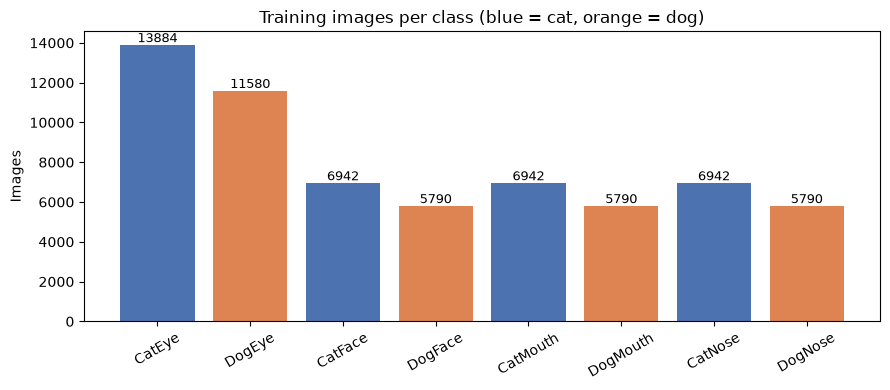

In [5]:
counts = train_df.label.value_counts().reindex(CLASSES_EXPECTED).fillna(0).astype(int)
print(counts.to_string())
imbalance_ratio = counts.max() / max(counts.min(), 1)
print(f"\nLargest/smallest class ratio: {imbalance_ratio:.2f}  (≈1 is balanced; >1.5 is worth addressing)")
for sp in ["Cat", "Dog"]:
    print(f"{sp}: Eye/Face = {counts[sp+'Eye'] / counts[sp+'Face']:.2f}, "
          f"Face = Nose = Mouth: {counts[sp+'Face'] == counts[sp+'Nose'] == counts[sp+'Mouth']}")
print(f"Cat/Dog image ratio: {counts[[c for c in CLASSES_EXPECTED if c.startswith('Cat')]].sum() / counts[[c for c in CLASSES_EXPECTED if c.startswith('Dog')]].sum():.2f}")

fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#4C72B0" if c.startswith("Cat") else "#DD8452" for c in counts.index]
ax.bar(counts.index, counts.values, color=colors)
for i, v in enumerate(counts.values): ax.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
ax.set_title("Training images per class (blue = cat, orange = dog)"); ax.set_ylabel("Images")
plt.xticks(rotation=30); plt.tight_layout(); plt.savefig(OUT/"class_distribution.png", dpi=150); plt.show()

### Representative samples from each class

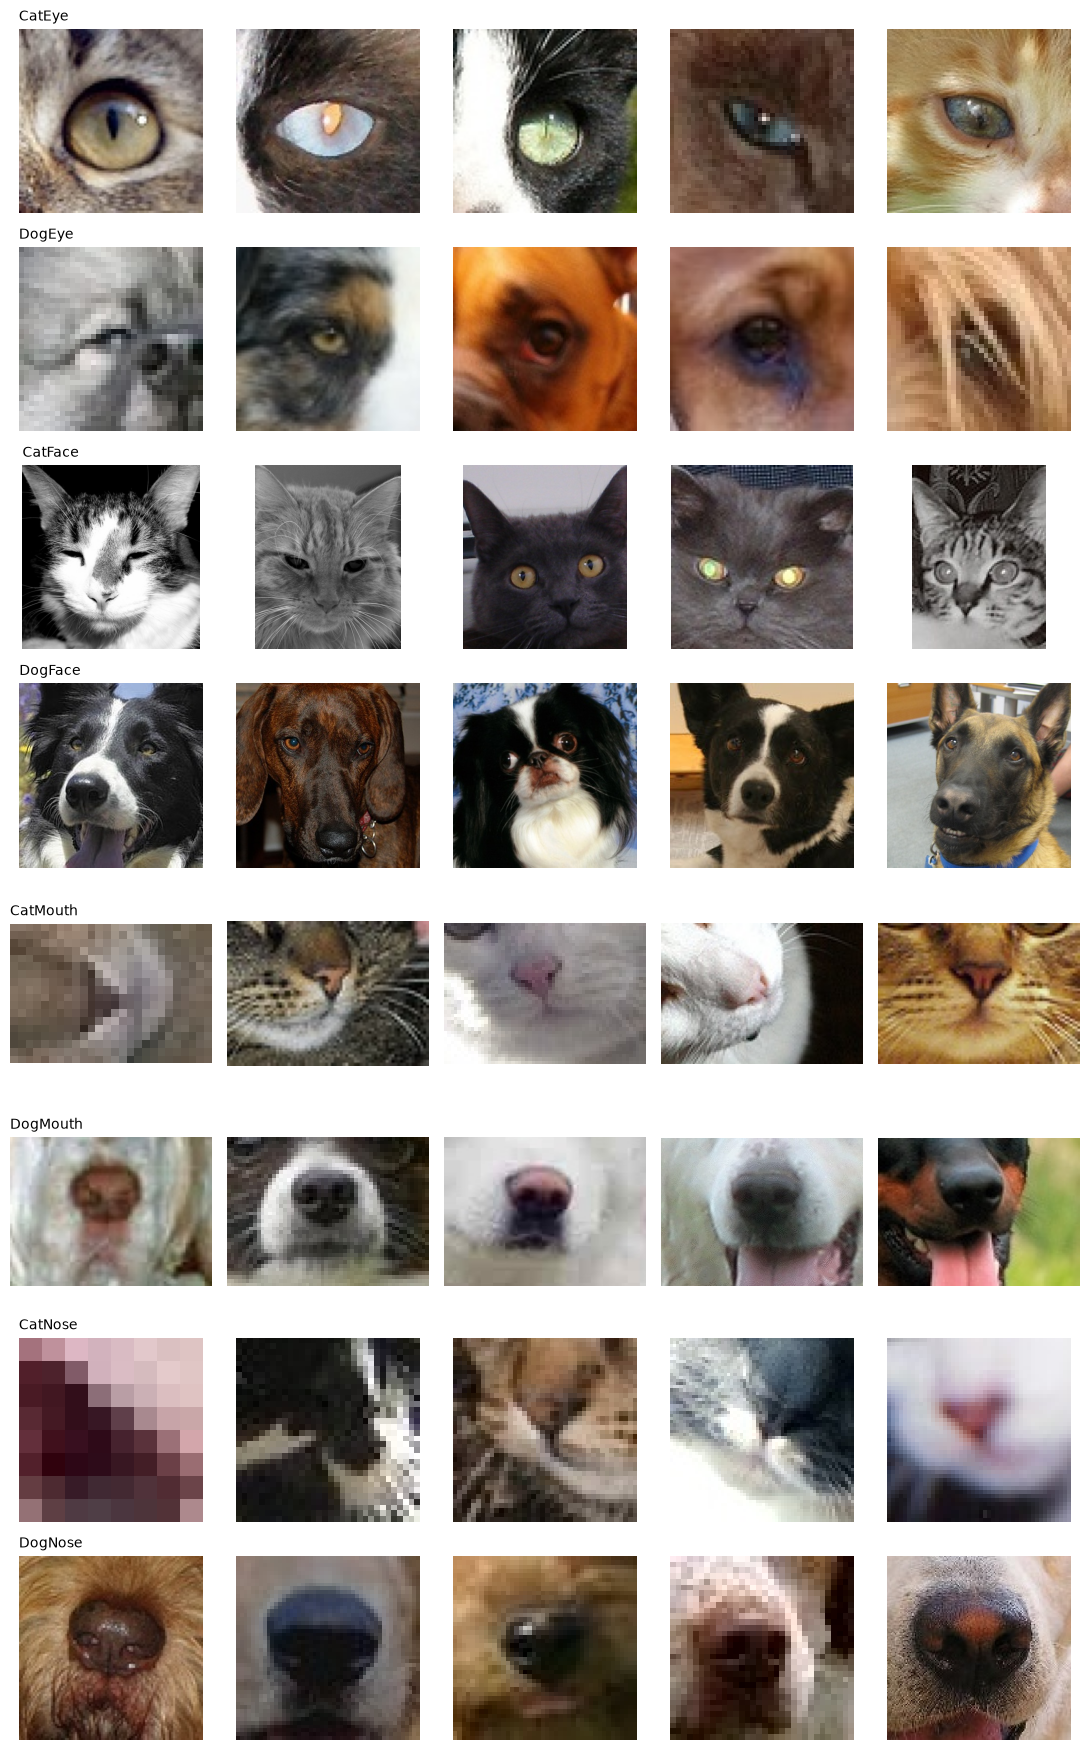

In [6]:
n_per_class = 5
fig, axes = plt.subplots(len(CLASSES_EXPECTED), n_per_class, figsize=(2.2*n_per_class, 2.2*len(CLASSES_EXPECTED)))
rng = np.random.default_rng(CFG["SEED"])
for r, cls in enumerate(CLASSES_EXPECTED):
    paths = train_df[train_df.label == cls].path.values
    picks = rng.choice(paths, size=min(n_per_class, len(paths)), replace=False) if len(paths) else []
    for c in range(n_per_class):
        ax = axes[r, c]; ax.axis("off")
        if c < len(picks):
            ax.imshow(Image.open(picks[c]).convert("RGB"))
        if c == 0: ax.set_title(cls, loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(OUT/"samples_per_class.png", dpi=120); plt.show()

### Data quality checks
* **Corrupted files** - images that fail to open
* **Image sizes / colour modes** - inconsistent sizes motivate resizing
* **Blur** - variance of an edge-filtered greyscale image (low = blurry)
* **Exact duplicates** - identical file hashes within training data, *and between train and test* (a leakage risk)

In [7]:
def inspect(path):
    try:
        with Image.open(path) as im:
            im.verify()                        # detects truncated / corrupted files
        with Image.open(path) as im:
            w, h = im.size; mode = im.mode
            g = im.convert("L").resize((128, 128))
            blur = np.asarray(g.filter(ImageFilter.FIND_EDGES), dtype=np.float32).var()
        md5 = hashlib.md5(open(path, "rb").read()).hexdigest()
        return dict(w=w, h=h, mode=mode, blur=blur, md5=md5, ok=True)
    except (UnidentifiedImageError, OSError, SyntaxError):
        return dict(w=np.nan, h=np.nan, mode=None, blur=np.nan, md5=None, ok=False)

# Reads every file once (~93k images); takes a few minutes. Results are cached to disk.
t0 = time.time()
q_train = pd.concat([train_df, pd.DataFrame([inspect(p) for p in train_df.path])], axis=1)
q_test  = pd.concat([test_df,  pd.DataFrame([inspect(p) for p in test_df.path])], axis=1)
print(f"Inspected {len(q_train)+len(q_test)} images in {time.time()-t0:.0f}s\n")
q_train.to_csv(OUT/"quality_train.csv", index=False); q_test.to_csv(OUT/"quality_test.csv", index=False)
print("Image size by class (median width x height):")
print(q_train.groupby("label")[["w", "h"]].median().reindex(CLASSES_EXPECTED).astype(int).to_string(), "\n")

print("Corrupted training files:", (~q_train.ok).sum(), "| corrupted test files:", (~q_test.ok).sum())
print("\nColour modes:", dict(Counter(q_train["mode"])))
print("\nImage size summary (training):"); print(q_train[["w", "h"]].describe().round(0).T)
print("\nMost common sizes:", Counter(zip(q_train.w, q_train.h)).most_common(5))

dup_groups = q_train[q_train.ok].groupby("md5").filter(lambda g: len(g) > 1)
conflicting = dup_groups.groupby("md5").label.nunique().gt(1).sum()
print(f"\nExact duplicate files in train: {len(dup_groups)} files in {dup_groups.md5.nunique()} groups "
      f"({conflicting} groups have CONFLICTING labels)")
cross = set(q_train.md5.dropna()) & set(q_test.md5.dropna())
print(f"Training images that also appear in the test set: {len(cross)}")

blur_thr = q_train.blur.quantile(0.02)
print(f"\nBlur score: 2nd percentile = {blur_thr:.1f}, median = {q_train.blur.median():.1f}")

Inspected 93103 images in 100s

Image size by class (median width x height):
            w    h
label             
CatEye     68   68
DogEye     62   62
CatFace   182  215
DogFace   155  155
CatMouth  114   80
DogMouth  104   77
CatNose    68   68
DogNose    62   62 

Corrupted training files: 0 | corrupted test files: 0

Colour modes: {'RGB': 63660}

Image size summary (training):
     count   mean    std  min   25%   50%    75%     max
w  63660.0  113.0   98.0  4.0  54.0  84.0  138.0  2219.0
h  63660.0  110.0  102.0  4.0  50.0  80.0  130.0  2219.0

Most common sizes: [((40, 40), 1062), ((48, 48), 1051), ((42, 42), 1050), ((38, 38), 1002), ((44, 44), 1002)]

Exact duplicate files in train: 30 files in 15 groups (0 groups have CONFLICTING labels)
Training images that also appear in the test set: 0

Blur score: 2nd percentile = 130.6, median = 1106.0


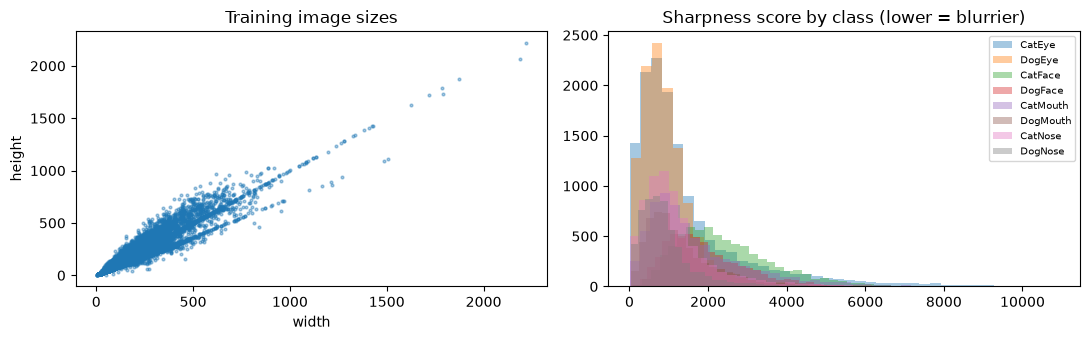

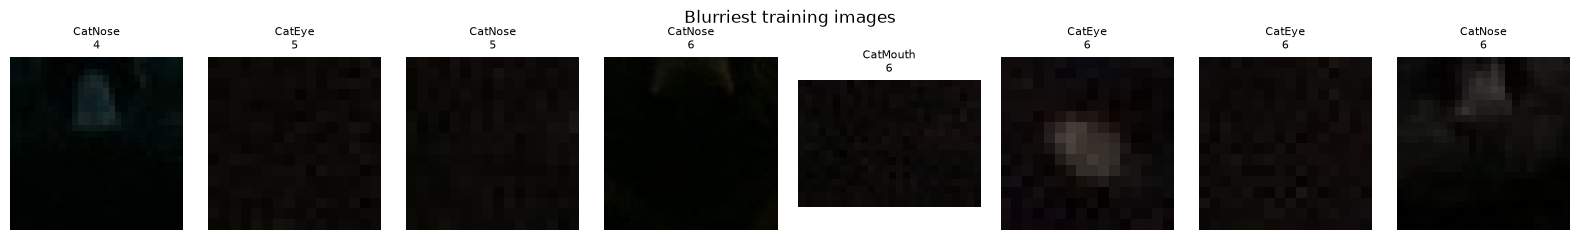

In [ ]:
# Size distribution and the blurriest images (inspect these for the report)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].scatter(q_train.w, q_train.h, s=4, alpha=0.4); axes[0].set_xlabel("width"); axes[0].set_ylabel("height")
axes[0].set_title("Training image sizes")
for cls in CLASSES_EXPECTED:
    axes[1].hist(q_train[q_train.label == cls].blur, bins=40, alpha=0.4, label=cls)
axes[1].set_title("Sharpness score by class (lower = blurrier)"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT/"sizes_and_blur.png", dpi=150); plt.show()

blurriest = q_train.nsmallest(8, "blur")
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, (_, r) in zip(axes, blurriest.iterrows()):
    ax.imshow(Image.open(r.path).convert("RGB")); ax.set_title(f"{r.label}\n{r.blur:.0f}", fontsize=8); ax.axis("off")
plt.suptitle("Blurriest training images"); plt.tight_layout(); plt.show()

In [ ]:
# ---------- Cleaning ----------
clean = q_train[q_train.ok].copy() # drop corrupted files
conflict_md5 = clean.groupby("md5").label.nunique().loc[lambda s: s > 1].index
clean = clean[~clean.md5.isin(conflict_md5)] # drop duplicates with contradictory labels
clean = clean.drop_duplicates("md5") # keep one copy of each duplicate
# Keeping one copy means no image can end up in BOTH train and validation -> prevents leakage
clean = clean[["path", "label"]].reset_index(drop=True)
print(f"Images after cleaning: {len(clean)} (removed {len(train_df) - len(clean)})")

Images after cleaning: 63645 (removed 15)


## 2. Preprocessing and pipeline preparation

### Label encoding and train/validation split
The cleaned training images were split 80/20 with stratification by class and a fixed seed (42). Stratification helps leep each class’s share the same in both sets, which matters with a 2.4 to 1 imbalance. 20% is about 12,700 images, with at least about 1,100 per class, which gives stable estimates. K-fold cross-validation would mean five times the training time for only little extra information at this size. The split was saved to CSV so every experiment used the same images.
Exact duplicates were removed before splitting so no file appears on both sides

In [ ]:
CLASSES = CLASSES_EXPECTED # fixed order -> stable label ids across runs
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
clean["y"] = clean.label.map(class_to_idx)

tr_df, va_df = train_test_split(clean, test_size=CFG["VAL_SIZE"], stratify=clean.y,
                                random_state=CFG["SEED"])
tr_df, va_df = tr_df.reset_index(drop=True), va_df.reset_index(drop=True)
tr_df.to_csv(OUT/"split_train.csv", index=False); va_df.to_csv(OUT/"split_val.csv", index=False)

print(f"Train: {len(tr_df)} | Val: {len(va_df)}")
print(pd.DataFrame({"train": tr_df.label.value_counts(), "val": va_df.label.value_counts()}).reindex(CLASSES))

Train: 50916 | Val: 12729
          train   val
label                
CatEye    11102  2775
DogEye     9261  2315
CatFace    5553  1389
DogFace    4630  1158
CatMouth   5553  1388
DogMouth   4632  1158
CatNose    5553  1388
DogNose    4632  1158


### Transforms and augmentation
- All images: resize to `IMG_SIZE`, convert to tensor (rescales pixels to [0, 1]), normalise with **ImageNet mean/std** because the backbone was pretrained with those statistics.
- Training only: random-resized crop with a **high minimum scale (0.7)**, horizontal flip, small rotation and mild colour jitter. Crops are kept gentle because cropping a face tightly can make it look like an eye or nose image, which would effectively change its label. Vertical flips are excluded since faces in real photos are rarely upside down.
- Validation and test images receive **only** the deterministic resize + normalise, so the same preprocessing is applied consistently and evaluation is not affected by randomness.

In [ ]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
S = CFG["IMG_SIZE"]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.7, 1.0), ratio=(0.85, 1.18)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((S, S)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class ImageDS(Dataset):
    # Loads images lazily from disk. Returns (tensor, label) or (tensor, -1) for unlabelled test images
    def __init__(self, df, tf):
        self.paths = df.path.values
        self.ys = df.y.values if "y" in df else np.full(len(df), -1)
        self.tf = tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")   # handles greyscale / RGBA / palette images
        return self.tf(img), int(self.ys[i])

g = torch.Generator().manual_seed(CFG["SEED"])
def worker_init(wid): np.random.seed(CFG["SEED"] + wid); random.seed(CFG["SEED"] + wid)
loader_kw = dict(batch_size=CFG["BATCH_SIZE"], num_workers=CFG["NUM_WORKERS"],
                 pin_memory=DEVICE.type == "cuda", worker_init_fn=worker_init)

train_dl = DataLoader(ImageDS(tr_df, train_tf), shuffle=True, generator=g, drop_last=True, **loader_kw)
val_dl   = DataLoader(ImageDS(va_df, eval_tf), shuffle=False, **loader_kw)
test_dl  = DataLoader(ImageDS(test_df, eval_tf), shuffle=False, **loader_kw)

## 3. Model selection and pipeline development

Transfer learning from an ImageNet-pretrained network instead of a custom CNN trained from scratch. ImageNet has over a hundred cat and dog categories, so its learned features (fur texture, eye and nose shapes, edges at different scales) are directly relevant. Fine-tuning these features needs far less data and training time than learning them from random weights.
* **Loss:** cross-entropy with label smoothing 0.1 (discourages over-confident predictions; helps with ambiguous crops).
* **Optimiser:** AdamW (Adam with decoupled weight decay), cosine learning-rate decay.
* **Two-stage training:** freeze the backbone and train only the new head for `FREEZE_EPOCHS`, then unfreeze and fine-tune everything at a lower learning rate. This stops large random-head gradients from damaging the pretrained features early on.

In [ ]:
def build_model(name, n_classes, dropout):
    if name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        in_f = m.classifier[1].in_features
        m.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_f, n_classes))
        head = m.classifier
    elif name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.fc.in_features, n_classes))
        head = m.fc
    elif name == "convnext_tiny":
        m = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
        in_f = m.classifier[2].in_features
        m.classifier[2] = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_f, n_classes))
        head = m.classifier
    else:
        raise ValueError(name)
    return m, head

model, head = build_model(CFG["MODEL_NAME"], len(CLASSES), CFG["DROPOUT"])
model = model.to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"{CFG['MODEL_NAME']}: {n_params/1e6:.2f}M parameters | input {CFG['IMG_SIZE']}x{CFG['IMG_SIZE']}x3 | output {len(CLASSES)} logits")
print(head)